# Exploratory Data Analysis

Dataset: [Semantic Segmentation of Underwater Imagery (SUIM)](https://irvlab.cs.umn.edu/resources/suim-dataset)
Resources:
- [github](https://github.com/xahidbuffon/SUIM)
- [arxiv paper](https://arxiv.org/pdf/2004.01241.pdf)
- [openaccess paper](https://openaccess.thecvf.com/content/ACCV2020/papers/Wang_Compact_and_Fast_Underwater_Segmentation_Network_for_Autonomous_Underwater_Vehicles_ACCV_2020_paper.pdf)


In [1]:
import cv2 as cv
import matplotlib.pyplot as plt
import numpy as np
import os
from tensorflow.keras.utils import to_categorical

In [2]:
data_path = 'input/'

train_path = os.path.join(data_path, 'train_val')
test_path = os.path.join(data_path, 'test')

train_images_path = os.path.join(train_path, 'images')
train_masks_path = os.path.join(train_path, 'masks')

test_images_path = os.path.join(test_path, 'images')
test_masks_path = os.path.join(test_path, 'masks')

class_names = [
    'Background (waterbody)', 'Human divers', 'Aquatic plants and sea-grass',
    'Wrecks and ruins', 'Robots (AUVs/ROVs/instruments)', 'Reefs and invertebrates',
    'Fish and vertebrates', 'Sea-floor and rocks',
]
num_classes = len(class_names)
class_codes = {
    0: (0, 0, 0),  # Black
    1: (0, 0, 1),  # Blue
    2: (0, 1, 0),  # Green
    3: (0, 1, 1),  # Sky
    4: (1, 0, 0),  # Red
    5: (1, 0, 1),  # Pink
    6: (1, 1, 0),  # Yellow
    7: (1, 1, 1),  # White
}
class_colors = ['black', 'blue', 'green', 'cyan', 'red', 'pink', 'yellow', 'orange']

for i, name in enumerate(class_names):
    print(f'Class {i}: {name}')

Class 0: Background (waterbody)
Class 1: Human divers
Class 2: Aquatic plants and sea-grass
Class 3: Wrecks and ruins
Class 4: Robots (AUVs/ROVs/instruments)
Class 5: Reefs and invertebrates
Class 6: Fish and vertebrates
Class 7: Sea-floor and rocks


### Load dataset

In [3]:
def list_files(path):
    content = os.listdir(path)
    # Get only files (not directories)
    files = [os.path.join(path, f) for f in content if os.path.isfile(os.path.join(path, f))]
    # Ensure the lists are sorted to match the corresponding image and mask
    files.sort()
    return files


train_image_files = list_files(train_images_path)
train_mask_files = list_files(train_masks_path)

test_image_files = list_files(test_images_path)
test_mask_files = list_files(test_masks_path)

print('Train images:', len(train_image_files))
print('Train masks:', len(train_mask_files))
print('Test images:', len(test_image_files))
print('Test masks:', len(test_mask_files))
print(f'Number of classes: {num_classes}')

for i in range(5):
    print(train_image_files[i], '|', train_mask_files[i])

Train images: 1525
Train masks: 1525
Test images: 110
Test masks: 110
Number of classes: 8
input/train_val\images\d_r_103_.jpg | input/train_val\masks\d_r_103_.bmp
input/train_val\images\d_r_105_.jpg | input/train_val\masks\d_r_105_.bmp
input/train_val\images\d_r_112_.jpg | input/train_val\masks\d_r_112_.bmp
input/train_val\images\d_r_113_.jpg | input/train_val\masks\d_r_113_.bmp
input/train_val\images\d_r_125_.jpg | input/train_val\masks\d_r_125_.bmp


Image shape: (480, 640, 3)
Mask shape: (480, 640, 3)
Image pixel values range [0, 255]
Mask pixel values range [0, 255]
Mask pixel values:
[[  0   0   0]
 [  0   0 255]
 [  0 255 255]
 [255 255 255]]


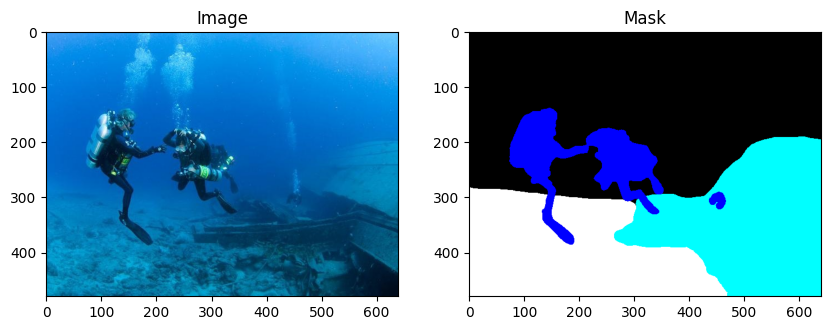

In [4]:
def read_image(path):
    # Load the image
    image = cv.imread(path, cv.IMREAD_COLOR)
    # Convert to RGB
    image = cv.cvtColor(image, cv.COLOR_BGR2RGB)
    return image


def unique_rgb_pixels(image):
    # Reshape the image to a 2D array (pixel_count x 3)
    reshaped_image = image.reshape(-1, 3)
    # Find the unique pixels in the reshaped image
    return np.unique(reshaped_image, axis=0)


example_image = read_image(train_image_files[0])
example_mask = read_image(train_mask_files[0])

print('Image shape:', example_image.shape)
print('Mask shape:', example_mask.shape)
print(f'Image pixel values range [{np.min(example_image)}, {np.max(example_image)}]')
print(f'Mask pixel values range [{np.min(example_mask)}, {np.max(example_mask)}]')
print(f'Mask pixel values:\n{unique_rgb_pixels(example_mask)}')

plt.figure(figsize=(10, 10))
plt.subplot(121)
plt.imshow(example_image)
plt.title('Image')
plt.subplot(122)
plt.imshow(example_mask)
plt.title('Mask')
plt.show()

In [5]:
def load_data(data_folder, normalize=True, resize=(640, 480)):
    images_folder = os.path.join(data_folder, 'images')
    masks_folder = os.path.join(data_folder, 'masks')

    image_names = os.listdir(images_folder)
    mask_names = os.listdir(masks_folder)

    images = []
    masks = []

    for image_name, mask_name in zip(image_names, mask_names):
        image_path = os.path.join(images_folder, image_name)
        mask_path = os.path.join(masks_folder, mask_name)

        # Filter out folders
        if not os.path.isfile(image_path) or not os.path.isfile(mask_path):
            continue

        # Load the image and mask
        image = cv.imread(image_path)
        mask = cv.imread(mask_path)

        # Resize the images to same size
        if resize is not None:
            image = cv.resize(image, resize, interpolation=cv.INTER_NEAREST)
            mask = cv.resize(mask, resize, interpolation=cv.INTER_NEAREST)

        # Convert the images to RGB
        image = cv.cvtColor(image, cv.COLOR_BGR2RGB)
        mask = cv.cvtColor(mask, cv.COLOR_BGR2RGB)

        # Normalize the images
        if normalize:
            image = image / 255.0
            mask = mask / 255.0

        images.append(image)
        masks.append(mask)

    return images, masks


train_images, train_masks = load_data(train_path, normalize=False, resize=None)
test_images, test_masks = load_data(test_path, normalize=False, resize=None)

### Inspect image resolution

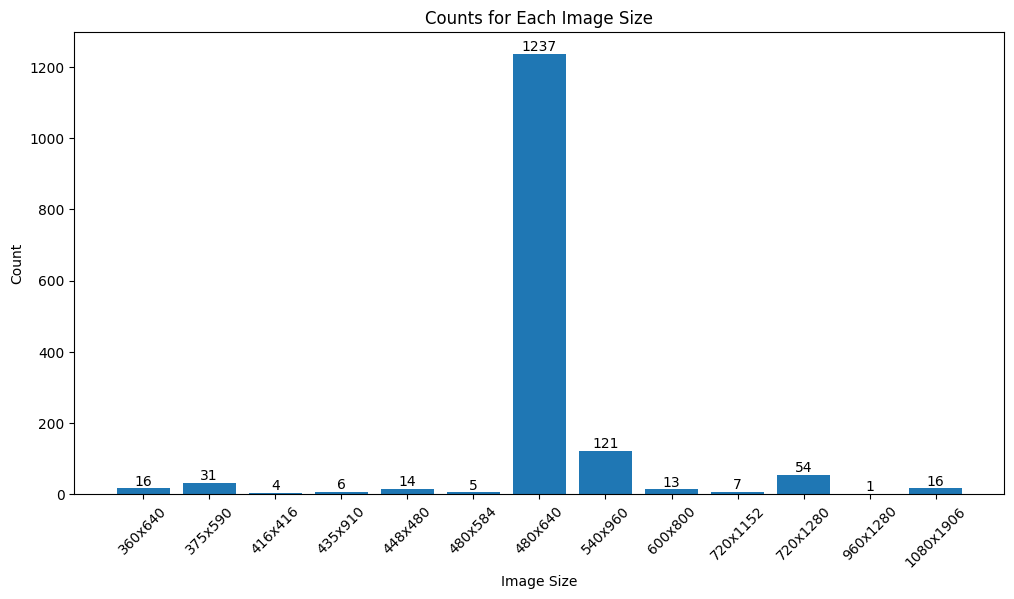

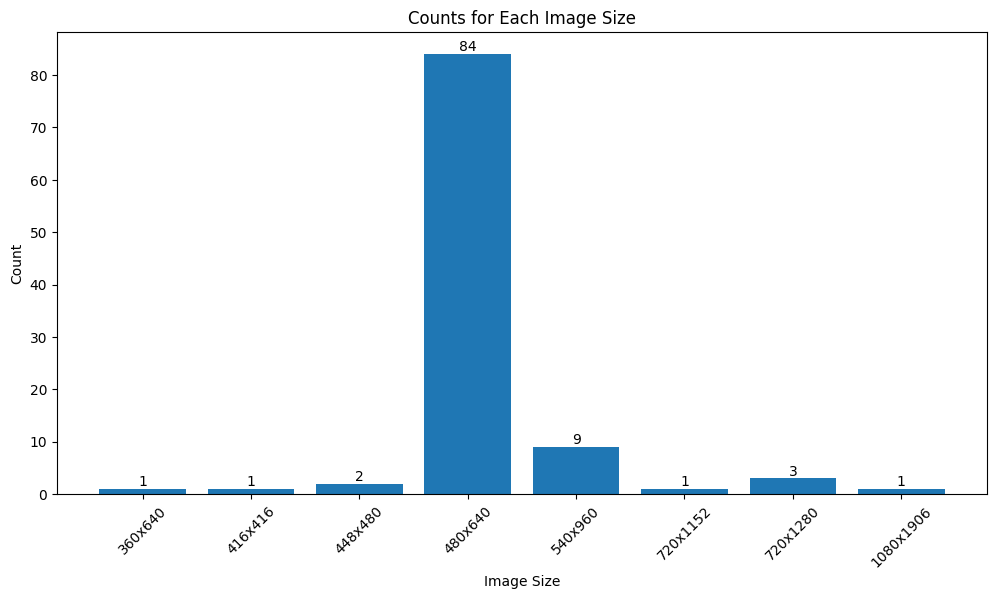

In [6]:
def plot_sizes_histogram(images, title):
    # Get the unique image sizes and their counts
    sizes = [image.shape for image in images]
    sizes, counts = np.unique(np.array(sizes), axis=0, return_counts=True)

    # Plot the histogram
    size_labels = [f'{s[0]}x{s[1]}' for s in sizes]
    plt.figure(figsize=(12, 6))
    bars = plt.bar(size_labels, counts)
    plt.xlabel('Image Size')
    plt.ylabel('Count')
    plt.title(title)
    plt.xticks(rotation=45)

    # Add count labels to each bar
    for bar, value in zip(bars, counts):
        height = bar.get_height()
        plt.text(bar.get_x() + bar.get_width() / 2, height, value, ha='center', va='bottom')
    plt.show()


plot_sizes_histogram(train_images, 'Histogram of image sizes in Train dataset')
plot_sizes_histogram(test_images, 'Histogram of image sizes in Test dataset')

### Visualize images and their masks

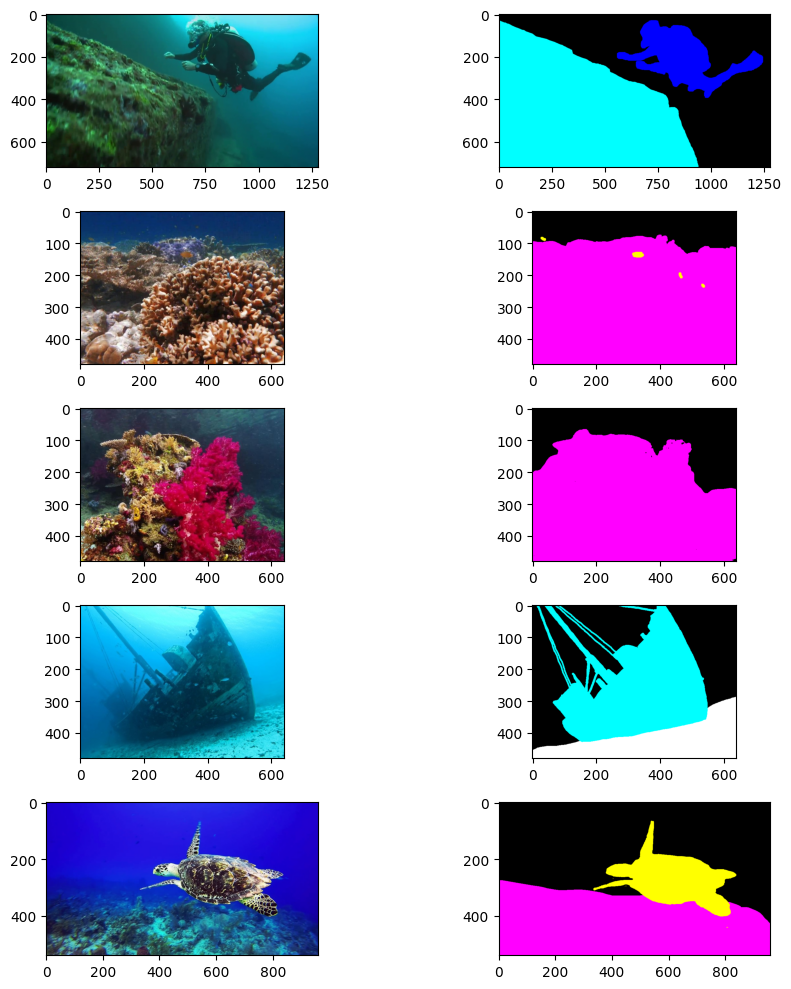

In [11]:
def plot_images(images, masks, n=5):
    fig, axes = plt.subplots(n, 2, figsize=(10, 10))

    # Randomly select n images and masks
    sample = np.random.randint(0, len(images), n)
    for i, j in enumerate(sample):
        axes[i, 0].imshow(images[j])
        axes[i, 1].imshow(masks[j])

    plt.tight_layout()
    plt.show()


plot_images(train_images, train_masks)

Loaded mask shape: (480, 640, 3)
Class id mask shape: (480, 640)
Unique pixel values in class id mask: [0 1 3 7]
Range of pixel values in class id mask [0, 7]


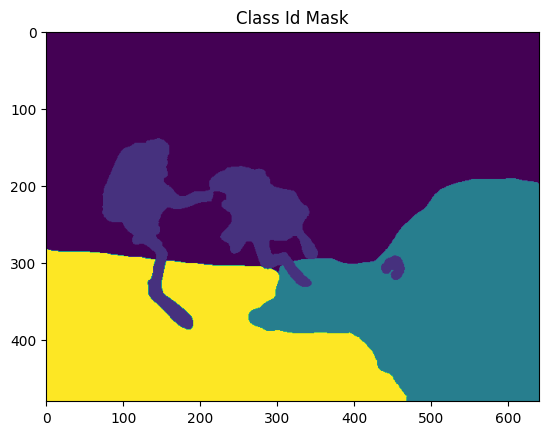

Reconstructed mask shape: (480, 640, 3)


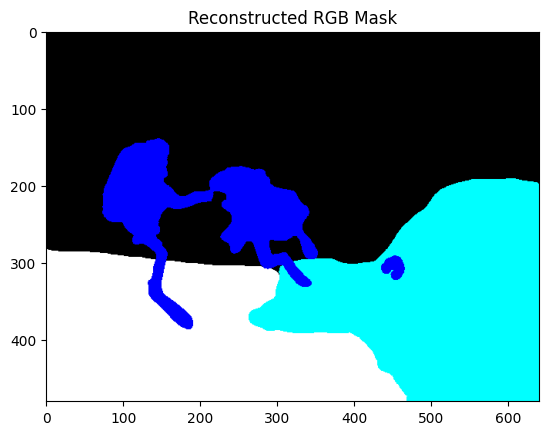

In [7]:
def rgb_to_label(image, label_codes, one_hot=True):
    label_image = np.zeros((image.shape[0], image.shape[1]), dtype=np.uint8)
    # Assigns each pixel a label from [0, num_classes - 1]
    for class_num, color in label_codes.items():
        label_image[np.all(image == color, axis=-1)] = class_num
    # Converts labeled image from (H, W) to (H, W, num_classes),
    # where each pixel is a one-hot vector (e.g. [2] => [0, 0, 1, 0, 0, 0, 0, 0])
    if one_hot:
        n_classes = len(label_codes)
        label_image = to_categorical(label_image, n_classes)
    return label_image


def label_to_rgb(image, label_codes, one_hot=True):
    rgb_image = np.empty((image.shape[0], image.shape[1], 3), dtype=np.float32)
    # Assigns each pixel a color from label_codes
    if one_hot:
        for class_num, color in label_codes.items():
            rgb_image[image[:, :, class_num] == 1] = color
    else:
        for class_num, color in label_codes.items():
            rgb_image[image == class_num] = color
    return rgb_image


mask = (example_mask / 255.0).astype(np.float32)
print('Loaded mask shape:', mask.shape)

encoded_mask = rgb_to_label(mask, class_codes, one_hot=False)
unique_pixels = np.unique(encoded_mask)
print('Class id mask shape:', encoded_mask.shape)
print('Unique pixel values in class id mask:', unique_pixels)
print(f'Range of pixel values in class id mask [{np.min(encoded_mask)}, {np.max(encoded_mask)}]')
plt.imshow(encoded_mask)
plt.title('Encoded Mask')
plt.show()

rgb_mask = label_to_rgb(encoded_mask, class_codes, one_hot=False)
print('Reconstructed mask shape:', rgb_mask.shape)
plt.imshow(rgb_mask)
plt.title('Reconstructed RGB Mask')
plt.show()

Loaded mask shape: (480, 640, 3)
One-hot mask shape: (480, 640, 8)
Unique pixel values in one-hot mask: [0. 1.]
Range of pixel values in one-hot mask [0.0, 1.0]


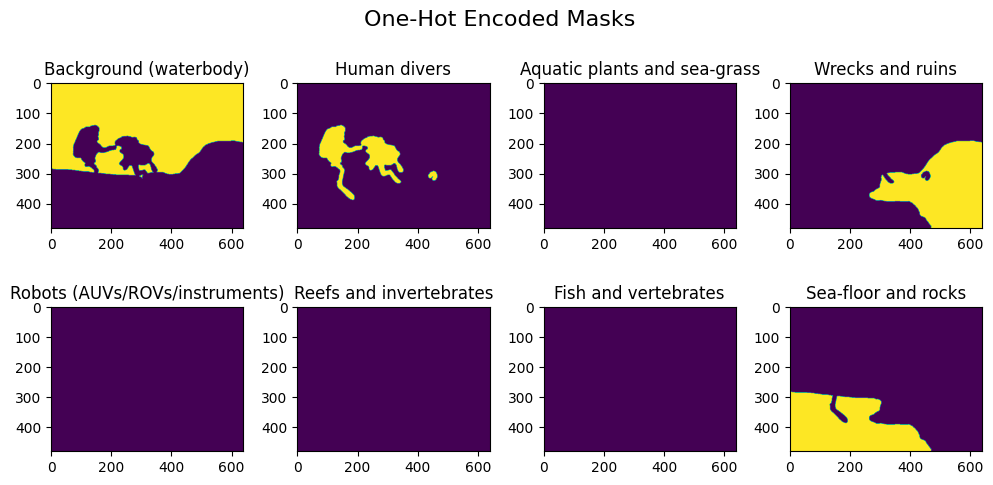

Reconstructed mask shape: (480, 640, 3)


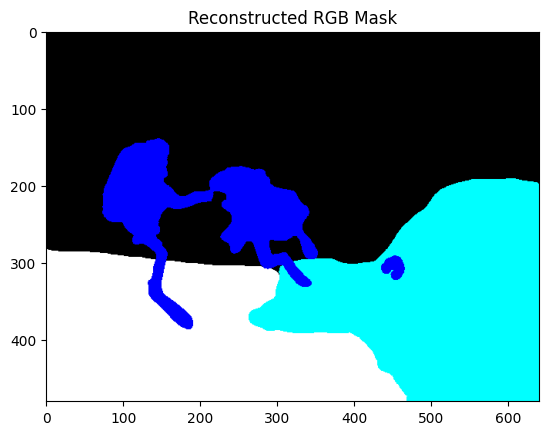

In [8]:
mask = (example_mask / 255.0).astype(np.float32)
print('Loaded mask shape:', mask.shape)

one_hot_mask = rgb_to_label(mask, class_codes, one_hot=True)
unique_pixels = np.unique(one_hot_mask)
print('One-hot mask shape:', one_hot_mask.shape)
print('Unique pixel values in one-hot mask:', unique_pixels)
print(f'Range of pixel values in one-hot mask [{np.min(one_hot_mask)}, {np.max(one_hot_mask)}]')

# plot images in 4x2 grid
fig, axes = plt.subplots(2, 4, figsize=(10, 5))
fig.suptitle('One-Hot Encoded Masks', fontsize=16)
for i, ax in enumerate(axes.flat):
    ax.imshow(one_hot_mask[:, :, i])
    ax.set_title(class_names[i])
plt.tight_layout()
plt.show()

rgb_mask = label_to_rgb(one_hot_mask, class_codes)
print('Reconstructed mask shape:', rgb_mask.shape)
plt.imshow(rgb_mask)
plt.title('Reconstructed RGB Mask')
plt.show()

In [9]:
# Fix invalid masks (masks with pixel values other than 0 or 255)
invalid_masks = []
for i, mask in enumerate(train_masks):
    # Check if every pixel is a 0 or 255
    if not np.all(np.logical_or(mask == 0, mask == 255)):
        invalid_masks.append(train_mask_files[i])
        # Round pixel values to 0 or 255
        fixed_mask = np.round(mask / 255.0) * 255.0
        train_masks[i] = fixed_mask
print('Found', len(invalid_masks), 'masks with invalid pixel values')

Found 85 masks with invalid pixel values


### Calculate class weights

In [10]:
# Calculate in how many images each class appears
category_image_counts = np.zeros(num_classes, dtype=np.int32)
for mask in train_masks:
    for class_id, class_color in class_codes.items():
        color = np.array(class_color) * 255.0
        if np.all(mask == color, axis=-1).any():
            category_image_counts[class_id] += 1
category_image_counts

array([1266,  387,  227,  266,  139, 1022, 1015,  633])

<Figure size 600x400 with 0 Axes>

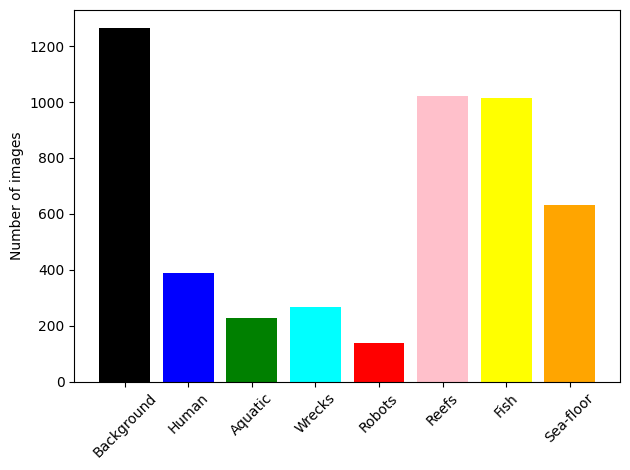

In [22]:
# Plot histogram of class counts
plt.figure(figsize=(6, 4))
names = list(map(lambda x: x.split(' ')[0], class_names))

# Create the bar plot with different colors for each column
fig, ax = plt.subplots()
for i, count in enumerate(category_image_counts):
    ax.bar(names[i], count, color=class_colors[i])

ax.set_ylabel('Number of images')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [11]:
# Calculate in how many images each class appears
category_pixel_counts = np.zeros(num_classes, dtype=np.int32)
for mask in train_masks:
    for class_id, class_color in class_codes.items():
        color = np.array(class_color) * 255.0
        category_pixel_counts[class_id] += np.sum(np.all(mask == color, axis=-1))
category_pixel_counts

array([180616009,  13085836,  12171698,  37532478,   4330207, 191308223,
        40011452,  78984741])

<Figure size 600x400 with 0 Axes>

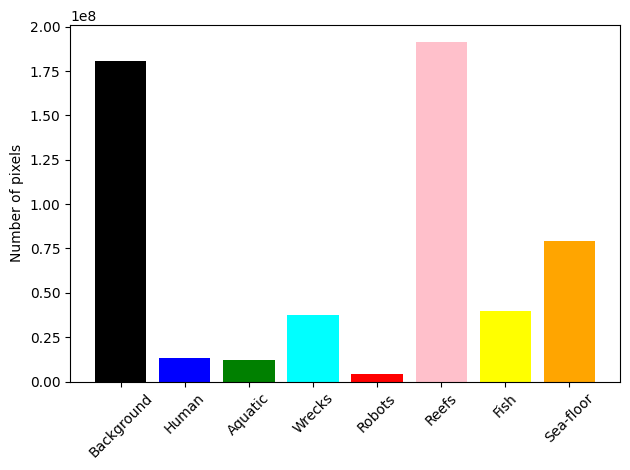

In [24]:
# Plot histogram of class counts
plt.figure(figsize=(6, 4))
names = list(map(lambda x: x.split(' ')[0], class_names))

# Create the bar plot with different colors for each column
fig, ax = plt.subplots()
for i, count in enumerate(category_pixel_counts):
    ax.bar(names[i], count, color=class_colors[i])

ax.set_ylabel('Number of pixels')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [26]:
# Calculate the class frequencies by counting the number of pixels belonging to each class in your training dataset
image_frequency = np.array([1266, 387, 227, 266, 139, 1022, 1015, 633])
pixel_frequency = np.array([180616009, 13085836, 12171698, 37532478, 4330207, 191308223, 40011452, 78984741])

# Normalize the class frequencies so that they sum up to 1
class_frequency = pixel_frequency / np.sum(pixel_frequency)

# Compute the inverse class frequencies (reciprocal of the normalized class frequencies)
inverse_class_frequency = 1 / class_frequency

# Normalize the inverse class frequencies so that the minimum weight is 1
class_weights = inverse_class_frequency / np.min(inverse_class_frequency)
class_weights

array([ 1.0591986 , 14.61948805, 15.71746382,  5.09713808, 44.17992558,
        1.        ,  4.78133668,  2.42209091])

### Data augmentation

In [15]:
import albumentations as A

data_augmentation = A.Compose([
    A.HorizontalFlip(p=0.5),
    # A.VerticalFlip(p=0.5),
    A.Rotate(limit=45, p=0.75, interpolation=cv.INTER_NEAREST, border_mode=cv.BORDER_REFLECT_101),
    A.OneOf([
        A.RandomBrightnessContrast(brightness_limit=0.2, contrast_limit=0.2, p=0.5),
        A.RandomGamma(gamma_limit=(80, 120), p=0.5),
    ], p=0.75),
    A.OneOf([
        A.Blur(blur_limit=3, p=0.5),
        A.MedianBlur(blur_limit=3, p=0.5),
    ], p=0.75),
])


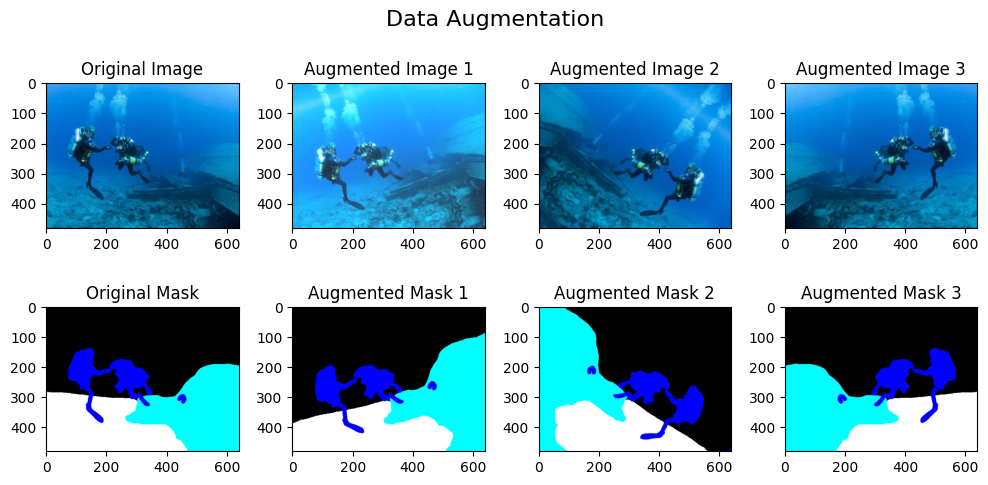

In [16]:
example_image = read_image(train_image_files[0])
example_mask = read_image(train_mask_files[0])

# Apply data augmentation
augmented = [data_augmentation(image=example_image, mask=example_mask) for _ in range(3)]
augmented_images = [a['image'] for a in augmented]
augmented_masks = [a['mask'] for a in augmented]

# Plot the original and augmented images
fig, axes = plt.subplots(2, 4, figsize=(10, 5))
fig.suptitle('Data Augmentation', fontsize=16)

axes[0, 0].imshow(example_image)
axes[0, 0].set_title('Original Image')
axes[1, 0].imshow(example_mask)
axes[1, 0].set_title('Original Mask')

for i, (image, mask) in enumerate(zip(augmented_images, augmented_masks)):
    axes[0, i + 1].set_title(f'Augmented Image {i + 1}')
    axes[0, i + 1].imshow(image)
    axes[1, i + 1].set_title(f'Augmented Mask {i + 1}')
    axes[1, i + 1].imshow(mask)

plt.tight_layout()
plt.show()